In [81]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [82]:
columnname=['area','bedrooms','price']
dataset=pd.read_csv("ex1data2.txt",names=columnname)

print(dataset)
dataset.shape

    area  bedrooms   price
0   2104         3  399900
1   1600         3  329900
2   2400         3  369000
3   1416         2  232000
4   3000         4  539900
5   1985         4  299900
6   1534         3  314900
7   1427         3  198999
8   1380         3  212000
9   1494         3  242500
10  1940         4  239999
11  2000         3  347000
12  1890         3  329999
13  4478         5  699900
14  1268         3  259900
15  2300         4  449900
16  1320         2  299900
17  1236         3  199900
18  2609         4  499998
19  3031         4  599000
20  1767         3  252900
21  1888         2  255000
22  1604         3  242900
23  1962         4  259900
24  3890         3  573900
25  1100         3  249900
26  1458         3  464500
27  2526         3  469000
28  2200         3  475000
29  2637         3  299900
30  1839         2  349900
31  1000         1  169900
32  2040         4  314900
33  3137         3  579900
34  1811         4  285900
35  1437         3  249900
3

(47, 3)

In [83]:
dataset.describe()
#therefore no missing values

,area,bedrooms,price
count,47.000000,47.000000,47.000000
mean,2000.680851,3.170213,340412.659574
std,794.702354,0.760982,125039.899586
min,852.000000,1.000000,169900.000000
25%,1432.000000,3.000000,249900.000000
50%,1888.000000,3.000000,299900.000000
75%,2269.000000,4.000000,384450.000000
max,4478.000000,5.000000,699900.000000


In [84]:
#normalistion---from -1 to 1
def featureNormalization(X):
    mean=np.mean(X,axis=0)
    std=np.std(X,axis=0)
    
    X_norm = (X - mean)/std
    
    return X_norm , mean , std

In [85]:
#.values converts dataframe to array
dt_norm=dataset.values
dt_norm

m2=len(dt_norm)
X2=dt_norm[:,0:2].reshape(m2,2)
Y2=dt_norm[:,2].reshape(m2,1)
print(X2.shape)
print(Y2.shape)

X2,mean_X2,std_X2=featureNormalization(X2)
# print(X2)
#we chose 1 as Q0 does not have weight Q0*1=Q0
#axis 1 means horizonotal append
X2 = np.append(np.ones((m2, 1)), X2, axis=1)
print(X2)
theta2=np.zeros((3,1))
print(theta2)
print(mean_X2)
print(std_X2)

(47, 2)
(47, 1)
[[ 1.00000000e+00  1.31415422e-01 -2.26093368e-01]
 [ 1.00000000e+00 -5.09640698e-01 -2.26093368e-01]
 [ 1.00000000e+00  5.07908699e-01 -2.26093368e-01]
 [ 1.00000000e+00 -7.43677059e-01 -1.55439190e+00]
 [ 1.00000000e+00  1.27107075e+00  1.10220517e+00]
 [ 1.00000000e+00 -1.99450507e-02  1.10220517e+00]
 [ 1.00000000e+00 -5.93588523e-01 -2.26093368e-01]
 [ 1.00000000e+00 -7.29685755e-01 -2.26093368e-01]
 [ 1.00000000e+00 -7.89466782e-01 -2.26093368e-01]
 [ 1.00000000e+00 -6.44465993e-01 -2.26093368e-01]
 [ 1.00000000e+00 -7.71822042e-02  1.10220517e+00]
 [ 1.00000000e+00 -8.65999486e-04 -2.26093368e-01]
 [ 1.00000000e+00 -1.40779041e-01 -2.26093368e-01]
 [ 1.00000000e+00  3.15099326e+00  2.43050370e+00]
 [ 1.00000000e+00 -9.31923697e-01 -2.26093368e-01]
 [ 1.00000000e+00  3.80715024e-01  1.10220517e+00]
 [ 1.00000000e+00 -8.65782986e-01 -1.55439190e+00]
 [ 1.00000000e+00 -9.72625673e-01 -2.26093368e-01]
 [ 1.00000000e+00  7.73743478e-01  1.10220517e+00]
 [ 1.00000000e+

In [86]:
def hypothesis(theta_array,x1,x2):
    return (theta_array[0]+theta_array[1]*x1+theta_array[2])*x2

In [87]:
def cost_function(thetha_array,x1_value,x2_train,y_value,m):
    total_error=0
    for i in range(m):
        total_error+=((thetha_array[0]+thetha_array[1]*x1_value[i]+x2_train[i]*thetha_array[2])-y_value[i])**2
    return (total_error/2*m)

In [88]:
def gradient_descent(thetha_array,x1,x2,y,m,alpha):
    sum0,sum1,sum2=0,0,0
    for i in range(m):
        sum0+=((thetha_array[0]+thetha_array[1]*x1[i]+thetha_array[2]*x2[i])-y[i])
        sum1+=x1[i]*((thetha_array[0]+thetha_array[1]*x1[i]+thetha_array[2]*x2[i])-y[i])
        sum2+=x2[i]*((thetha_array[0]+thetha_array[1]*x1[i]+thetha_array[2]*x2[i])-y[i])
    update_thetha0=thetha_array[0]-(alpha/m)*sum0
    update_thetha1=thetha_array[1]-(alpha/m)*sum1
    update_thetha2=thetha_array[2]-(alpha/m)*sum2
    new_thetha=[update_thetha0,update_thetha1,update_thetha2]
    return new_thetha

In [89]:
def training(x1_train,x2_train,y_train,alpha,iters):
    theta0,theta1,theta2=0,0,0
    theta_array=[theta0,theta1,theta2]
    m=x1_train.size
    cost_value=[]
    for i in range(iters):
        theta_array=gradient_descent(theta_array,x1_train,x2_train,y_train,m,alpha)
        cost_value.append(cost_function(theta_array,x1_train,x2_train,y_train,m))
        y_new=theta_array[0]+theta_array[1]*x1_train+theta_array[2]*x2_train
        # plt.plot(x1_train,y_new,'r')
        # plt.scatter(x1_train,y_train)
        # plt.show()
    plt.figure()
    x=np.arange(0,len(cost_value),step=1)
    plt.plot(x,cost_value)
    plt.xlabel("Number Of Iterations")
    plt.ylabel("Cost Function Value")
    plt.show()
    return theta_array

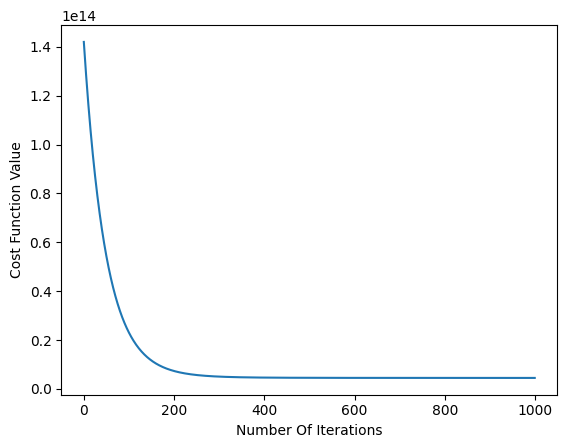

In [90]:
alpha=0.01
iters=1000


price_value = dataset.iloc[0:dataset.shape[0],2:3]
price_value

theta_array=training(X2[:,1:2],X2[:,2:3],Y2,alpha,iters)